In [ ]:
!pip install -U structured-data-models

In [ ]:
import torch
import sdm
import pandas as pd
import numpy as np

import random
import torch

import time
import gc

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt
import seaborn as sns

from sdm import TableTensor, Task
from sdm.models import (
    TabICLv2,
    TabFM,
    KumoTabular
)

from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error

In [ ]:
X_train = pd.read_csv('X_train_sel.csv')
X_test = pd.read_csv('X_test_sel.csv')
y_train = pd.read_csv('y_train_sel.csv').iloc[:, 0]
y_test = pd.read_csv('y_test_sel.csv').iloc[:, 0]

In [ ]:
X_train = X_train.drop(columns=['sn'])
X_test = X_test.drop(columns=['sn'])

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1192, 19)
X_test: (298, 19)
y_train: (1192,)
y_test: (298,)


In [ ]:
# Identify feature types
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [ ]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA: True
GPU: Tesla T4


In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set the random seed for reproducibility
set_seed(42)

In [ ]:
# Preprocessing
numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [ ]:
# Combine train and test features
X_all = pd.concat([X_train, X_test], ignore_index=True)

# Combine target: train labels + missing test labels
y_all = pd.concat([
    y_train.reset_index(drop=True),
    pd.Series([None] * len(X_test))
], ignore_index=True)

# Add target column
data = X_all.copy()
data['target'] = y_all

In [ ]:
stypes = {}

for col in X_all.columns:
    if pd.api.types.is_numeric_dtype(X_all[col]):
        stypes[col] = "numerical"
    else:
        stypes[col] = "categorical"

stypes['target'] = "numerical"

In [ ]:
table = TableTensor.from_columns(
    data.to_dict(orient='list'),
    stypes=stypes,
    device='cuda'
)

In [ ]:
tabicl = TabICLv2(device="cuda")

out_icl = tabicl(
    x_context=table[:len(X_train)].drop_columns("target"),
    y_context=table[:len(X_train), "target"],
    x_query=table[len(X_train):].drop_columns("target"),
)

tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            

tabicl-regressor-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  114MB            

tabicl-regressor-v2-20260212.ckpt: downloading bytes:           |  0.00B            

In [ ]:
y_pred_tabicl = out_icl["q500"].numerical.cpu().numpy()
y_pred_tabicl = y_pred_tabicl.reshape(-1)
y_pred_tabicl = np.maximum(y_pred_tabicl, 0.000001)

In [ ]:
n_train = len(X_train)
x_context = table[:n_train].drop_columns("target")
y_context = table[:n_train, "target"]
x_query = table[n_train:].drop_columns("target")

In [ ]:
model_tabfm = TabFM(
    task=Task.regression,
    accept_license=True,
    device="cuda"
)

out_tabfm = model_tabfm(
    x_context=x_context,
    y_context=y_context,
    x_query=x_query
)

print(out_tabfm)
print(out_tabfm.to_pandas().head())

regression/model.safetensors: reconstructing file:   0%|          |  0.00B / 6.59GB            

regression/model.safetensors: downloading bytes:           |  0.00B            

TableTensor(
  size=(298, 1),
  blocks={
    numerical (1): [pred],
  },
  device=cuda:0,
)
         pred
0    0.701691
1  124.457230
2  -15.680786
3   69.288795
4    4.851791


In [ ]:
tabfm_df = out_tabfm.to_pandas()
y_pred_tabfm = tabfm_df.iloc[:, 0].to_numpy().reshape(-1)
y_pred_tabfm = np.maximum(y_pred_tabfm, 0.000001)

In [ ]:
model_kumo = KumoTabular(
    task=Task.regression,
    size="small",
    device="cuda"
)

out_kumo = model_kumo(
    x_context=x_context,
    y_context=y_context,
    x_query=x_query
)

print(out_kumo)
print(out_kumo.shape)

config.json:   0%|          | 0.00/423 [00:00<?, ?B/s]

small/regressor.pt: reconstructing file:   0%|          |  0.00B /  114MB            

small/regressor.pt: downloading bytes:           |  0.00B            

TableTensor(
  size=(298, 999),
  blocks={
    numerical (999): [q001, q002, ..., q999],
  },
  device=cuda:0,
)
torch.Size([298, 999])


In [ ]:
kumo_df = out_kumo.to_pandas()
y_pred_kumo = out_kumo["q500"].numerical.cpu().numpy().reshape(-1)
y_pred_kumo = np.maximum(y_pred_kumo, 0.000001)

In [ ]:
evaluation_ptfm_MIC = pd.DataFrame([
    {
        "Model": "Kumo",
        "MAE": mean_absolute_error(y_test, y_pred_kumo),
        "MSE": mean_squared_error(y_test, y_pred_kumo),
        "RMSE": root_mean_squared_error(y_test, y_pred_kumo),
        "R2": r2_score(y_test, y_pred_kumo)
    },
    {
        "Model": "TabFM",
        "MAE": mean_absolute_error(y_test, y_pred_tabfm),
        "MSE": mean_squared_error(y_test, y_pred_tabfm),
        "RMSE": root_mean_squared_error(y_test, y_pred_tabfm),
        "R2": r2_score(y_test, y_pred_tabfm)
    },
    {
        "Model": "TabICL",
        "MAE": mean_absolute_error(y_test, y_pred_tabicl),
        "MSE": mean_squared_error(y_test, y_pred_tabicl),
        "RMSE": root_mean_squared_error(y_test, y_pred_tabicl),
        "R2": r2_score(y_test, y_pred_tabicl)
    }
])

evaluation_ptfm_MIC = evaluation_ptfm_MIC.round(4)

print(evaluation_ptfm_MIC)

    Model       MAE          MSE      RMSE      R2
0    Kumo   79.4957  291033.1276  539.4749  0.5432
1   TabFM  111.8483  319889.7062  565.5879  0.4979
2  TabICL   66.9055  125519.5059  354.2873  0.8030


In [ ]:
evaluation_ptfm_MIC.to_csv(
    "overallresult_ptfm_MIC.csv",
    index=False
)

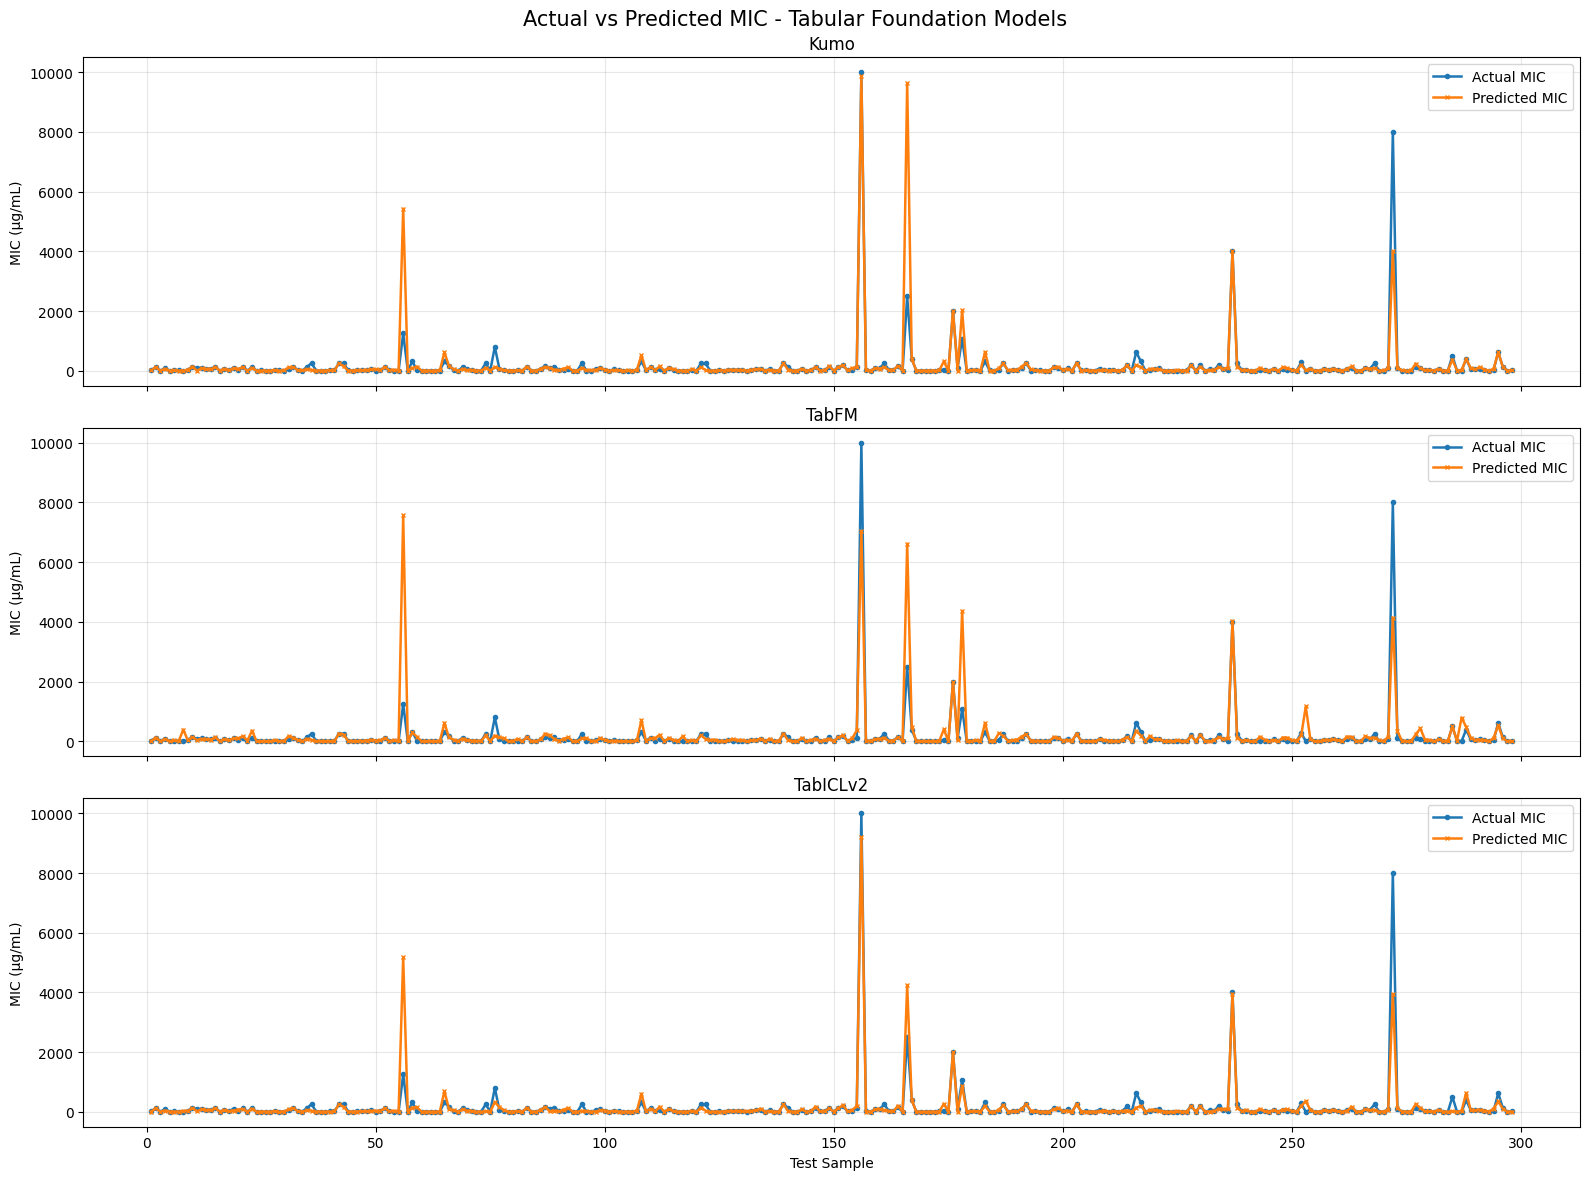

In [ ]:
predictions = {
    "Kumo": y_pred_kumo,
    "TabFM": y_pred_tabfm,
    "TabICLv2": y_pred_tabicl
}

actual = np.asarray(y_test).reshape(-1)
samples = np.arange(1, len(actual) + 1)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax, (name, pred) in zip(axes, predictions.items()):

    pred = np.asarray(pred).reshape(-1)

    ax.plot(samples, actual, label="Actual MIC",
            linewidth=1.8, marker='o', markersize=3)

    ax.plot(samples, pred, label="Predicted MIC",
            linewidth=1.8, marker='x', markersize=3)

    ax.set_title(name)
    ax.set_ylabel("MIC (µg/mL)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Test Sample")

plt.suptitle(
    "Actual vs Predicted MIC - Tabular Foundation Models",
    fontsize=15
)

plt.tight_layout()
plt.show()

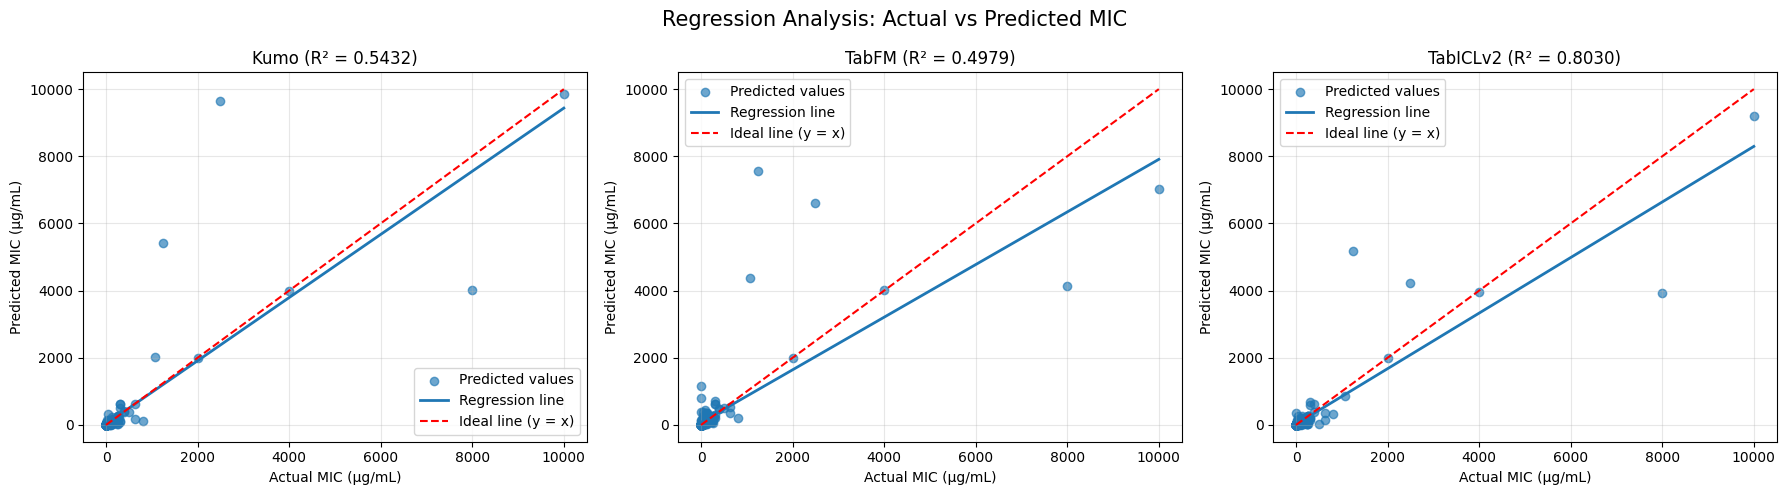

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    pred = np.asarray(pred).reshape(-1)

    # Scatter plot
    ax.scatter(actual, pred, alpha=0.65, label="Predicted values")

    # Regression line
    slope, intercept = np.polyfit(actual, pred, 1)
    x_line = np.linspace(actual.min(), actual.max(), 100)
    y_line = slope * x_line + intercept

    ax.plot(x_line, y_line, linewidth=2, label="Regression line")

    # Perfect prediction line
    ax.plot(
        [actual.min(), actual.max()],
        [actual.min(), actual.max()],
        'r--',
        linewidth=1.5,
        label="Ideal line (y = x)"
    )

    r2 = r2_score(actual, pred)

    ax.set_title(f"{name} (R² = {r2:.4f})")
    ax.set_xlabel("Actual MIC (µg/mL)")
    ax.set_ylabel("Predicted MIC (µg/mL)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Regression Analysis: Actual vs Predicted MIC", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
eval_df = pd.DataFrame({
    'actual': actual,
    'Kumo': y_pred_kumo,
    'TabFM': y_pred_tabfm,
    'TabICL': y_pred_tabicl
})

quantile_labels = ['Q1 (0-25%)', 'Q2 (25-50%)', 'Q3 (50-75%)', 'Q4 (75-100%)']
eval_df['quantile'] = pd.qcut(eval_df['actual'], q=4, labels=quantile_labels)

quantile_results = []

for q in quantile_labels:
    df_q = eval_df[eval_df['quantile'] == q]

    q_min = df_q['actual'].min()
    q_max = df_q['actual'].max()

    for model_name in ['Kumo', 'TabFM', 'TabICL']:
        y_true_q = df_q['actual']
        y_pred_q = df_q[model_name]

        try:
            r2 = r2_score(y_true_q, y_pred_q)
        except:
            r2 = np.nan

        quantile_results.append({
            'Model': model_name,
            'Quantile': q,
            'N': len(df_q),
            'MIC range': f"[{q_min:.2f}, {q_max:.2f}]",
            'MAE': mean_absolute_error(y_true_q, y_pred_q),
            'MSE': mean_squared_error(y_true_q, y_pred_q),
            'RMSE': np.sqrt(mean_squared_error(y_true_q, y_pred_q)),
            'R2': r2
        })

df_by_quantile = pd.DataFrame(quantile_results).round(4)
display(df_by_quantile)

,Model,Quantile,N,MIC range,MAE,MSE,RMSE,R2
0,Kumo,Q1 (0-25%),76,"[0.00, 5.00]",2.6989,2.594640e+01,5.0938,-10.4259
1,TabFM,Q1 (0-25%),76,"[0.00, 5.00]",37.0551,2.835093e+04,168.3773,-12483.7977
2,TabICL,Q1 (0-25%),76,"[0.00, 5.00]",7.4113,1.698453e+03,41.2123,-746.9419
3,Kumo,Q2 (25-50%),74,"[5.10, 20.00]",8.3127,4.100807e+02,20.2505,-24.5917
4,TabFM,Q2 (25-50%),74,"[5.10, 20.00]",17.4841,1.086768e+03,32.9662,-66.8214
5,TabICL,Q2 (25-50%),74,"[5.10, 20.00]",7.5218,3.827735e+02,19.5646,-22.8876
6,Kumo,Q3 (50-75%),74,"[22.50, 78.79]",19.1345,1.711181e+03,41.3664,-3.9252
7,TabFM,Q3 (50-75%),74,"[22.50, 78.79]",42.2020,6.230203e+03,78.9316,-16.9319
8,TabICL,Q3 (50-75%),74,"[22.50, 78.79]",21.8052,1.593951e+03,39.9243,-3.5878
9,Kumo,Q4 (75-100%),74,"[80.00, 10000.00]",289.9124,1.169850e+06,1081.5962,0.4980


In [ ]:
df_by_quantile.to_csv(
    "quantileresult_ptfm_MIC.csv",
    index=False
)

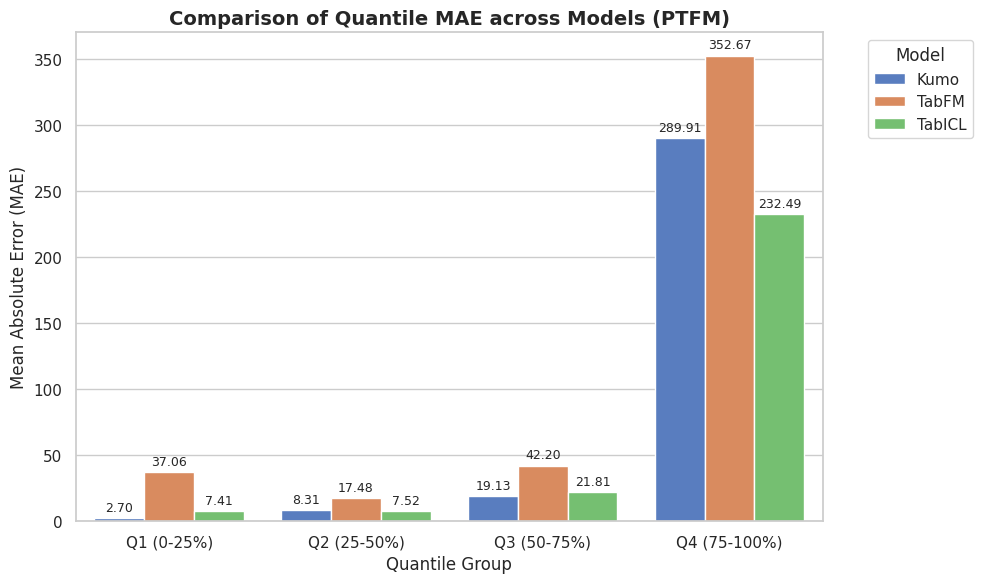

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_by_quantile,
    x='Quantile',
    y='MAE',
    hue='Model',
    palette='muted'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

plt.title('Comparison of Quantile MAE across Models (PTFM)', fontsize=14, fontweight='bold')
plt.xlabel('Quantile Group', fontsize=12)
plt.ylabel('Mean Absolute Error (MAE)', fontsize=12)
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.savefig('quantile_mae_comparison.png', dpi=300)
plt.show()

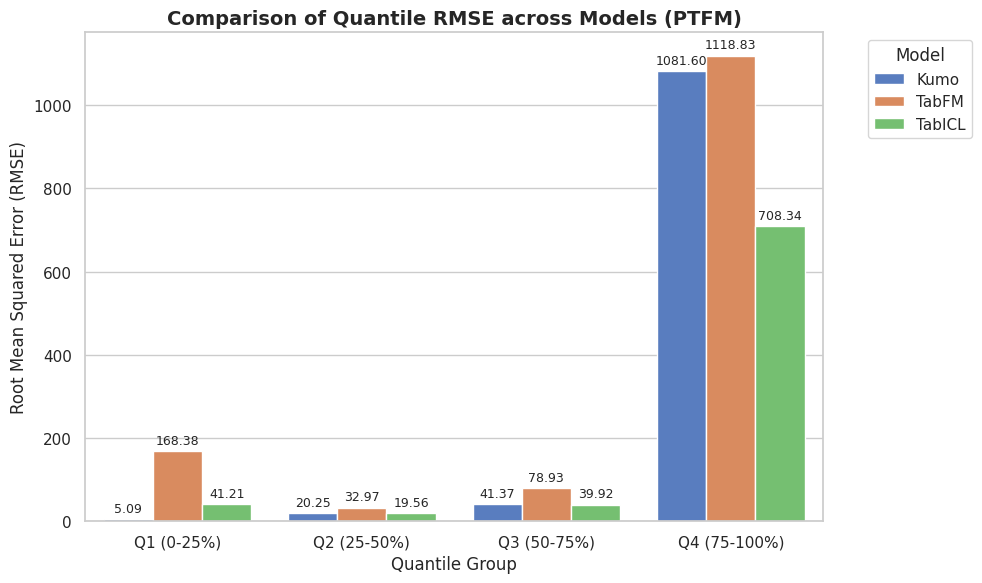

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax_rmse = sns.barplot(
    data=df_by_quantile,
    x='Quantile',
    y='RMSE',
    hue='Model',
    palette='muted'
)

for container in ax_rmse.containers:
    ax_rmse.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

plt.title('Comparison of Quantile RMSE across Models (PTFM)', fontsize=14, fontweight='bold')
plt.xlabel('Quantile Group', fontsize=12)
plt.ylabel('Root Mean Squared Error (RMSE)', fontsize=12)
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.savefig('quantile_rmse_comparison.png', dpi=300)
plt.show()